**Task 1: Data Acquisition & Exploratory Data Analysis (EDA)**

In [ ]:
import pandas as pd
import numpy as np

columns = [
    'age','sex','cp','trestbps','chol',
    'fbs','restecg','thalach',
    'exang','oldpeak','slope',
    'ca','thal','target'
]

files = [
    "processed.cleveland.data",
    "processed.hungarian.data",
    "processed.switzerland.data",
    "processed.va.data"
]

dfs = []

for file in files:
    df = pd.read_csv(file, header=None, names=columns)
    dfs.append(df)

heart_df = pd.concat(dfs, ignore_index=True)

heart_df.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


**Data Cleaning**

In [ ]:
#Replaced missing values represented as '?'
heart_df.replace('?', np.nan, inplace=True)

#Converted all features to numeric format.
for col in heart_df.columns:
    heart_df[col] = pd.to_numeric(
        heart_df[col],
        errors='coerce'
    )

# Convert multi-class target into binary classification.
heart_df['target'] = (
    heart_df['target'] > 0
).astype(int)

heart_df.to_csv(
    "heart_disease_combined.csv",
    index=False
)

print(heart_df.shape)
print(heart_df.head())

(920, 14)
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       1  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  


In [ ]:
#Step 1: Missing Value Analysis
print("Missing Values:")
print(heart_df.isnull().sum())

missing_percent = (
    heart_df.isnull().sum() /
    len(heart_df)
) * 100

print("\nMissing Percentage:")
print(f"{missing_percent.round(2)}")

Missing Values:
age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalach      55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
target        0
dtype: int64

Missing Percentage:
age          0.00
sex          0.00
cp           0.00
trestbps     6.41
chol         3.26
fbs          9.78
restecg      0.22
thalach      5.98
exang        5.98
oldpeak      6.74
slope       33.59
ca          66.41
thal        52.83
target       0.00
dtype: float64


In [ ]:
#Handle Missing Values, replace with median
for col in heart_df.columns:
    heart_df[col] = heart_df[col].fillna(
        heart_df[col].median()
    )

print(heart_df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
#Basic Dataset Information
print(heart_df.info())

print("\nStatistical Summary:")
print(heart_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  920 non-null    float64
 4   chol      920 non-null    float64
 5   fbs       920 non-null    float64
 6   restecg   920 non-null    float64
 7   thalach   920 non-null    float64
 8   exang     920 non-null    float64
 9   oldpeak   920 non-null    float64
 10  slope     920 non-null    float64
 11  ca        920 non-null    float64
 12  thal      920 non-null    float64
 13  target    920 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 100.8 KB
None

Statistical Summary:
              age         sex          cp    trestbps        chol         fbs  \
count  920.000000  920.000000  920.000000  920.000000  920.000000  920.000000   
mean    53.510870    0.789130

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

/tmp/ipykernel_30444/1523344038.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


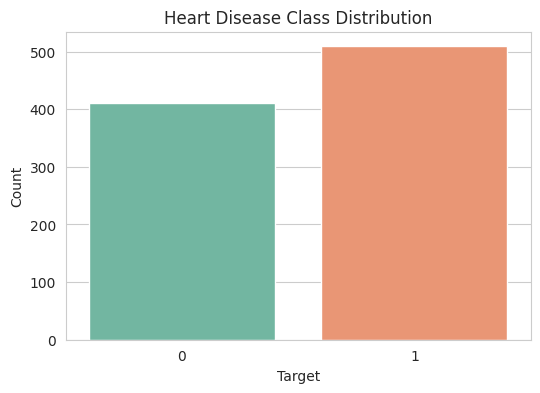

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='target',
    data=heart_df,
    palette='Set2'
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Target")
plt.ylabel("Count")

plt.show()

Observation - The dataset shows a reasonably balanced distribution between heart disease and non-heart disease cases, reducing the risk of severe class imbalance during model training.

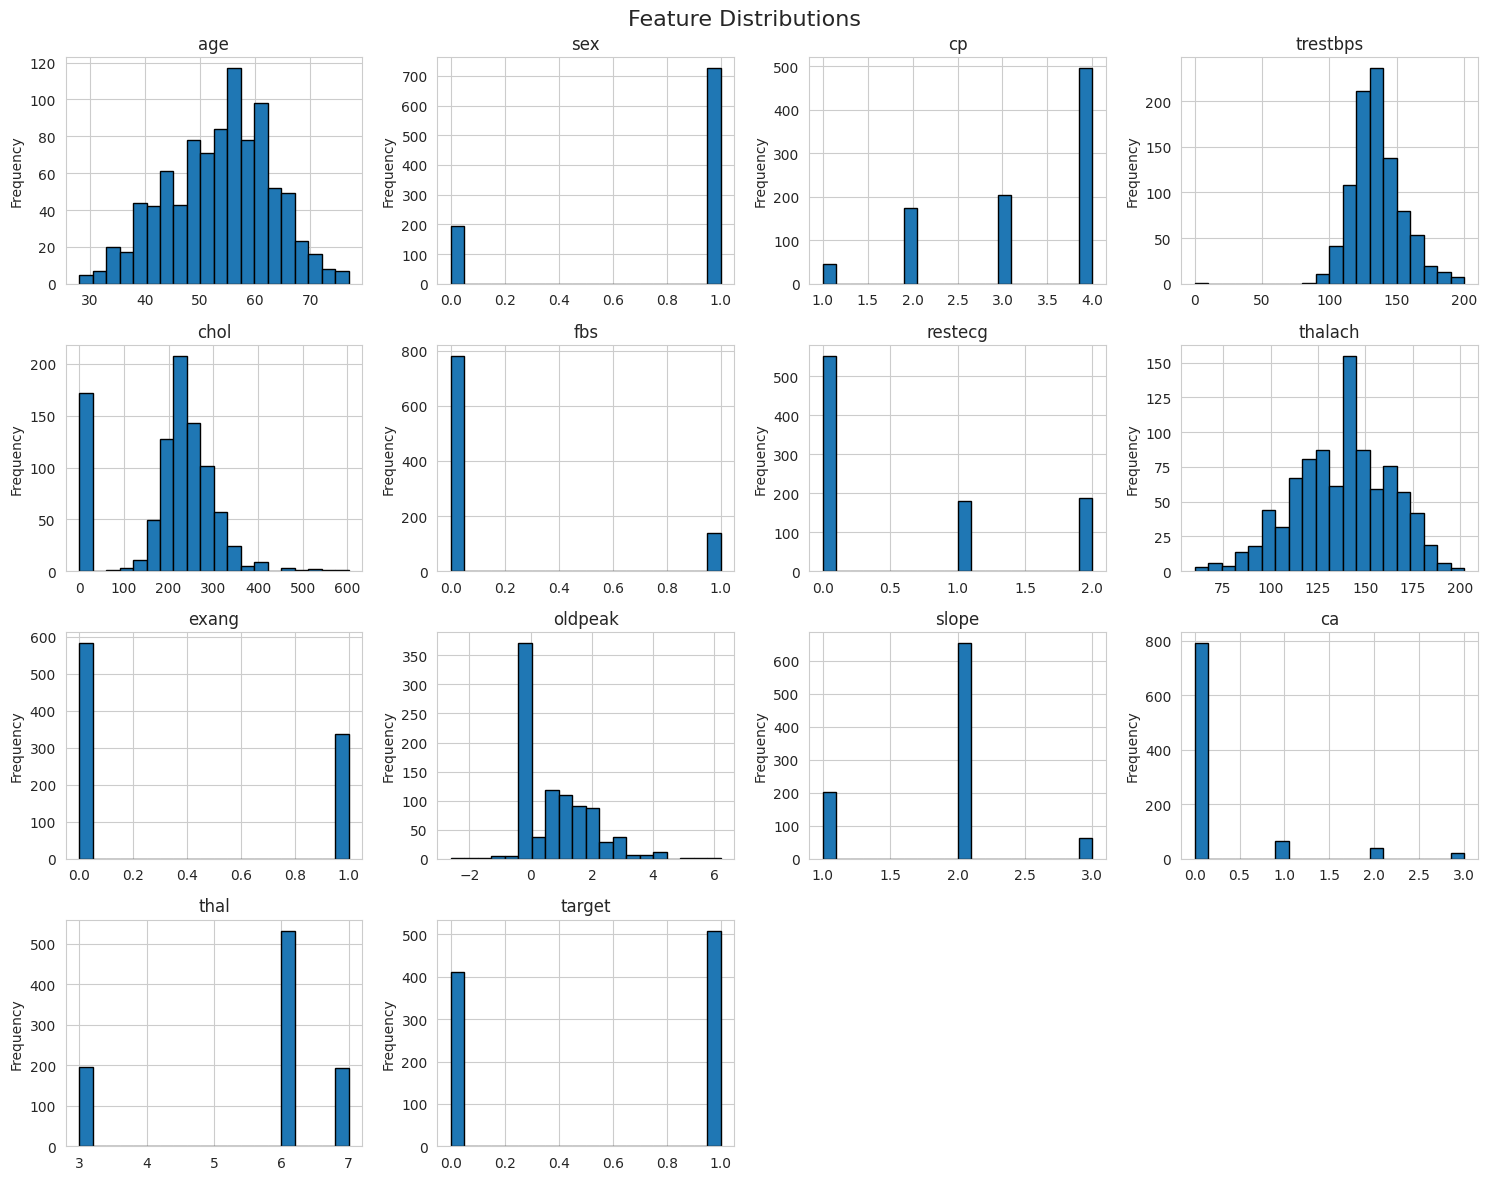

In [ ]:
import matplotlib.pyplot as plt

axes = heart_df.hist(
    figsize=(15,12),
    bins=20,
    edgecolor='black'
)

for ax in axes.flatten():
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

Observation - The histograms show that most patients are middle-aged, cholesterol and blood pressure contain some outliers, and maximum heart rate follows a roughly normal distribution. Several categorical features such as sex, chest pain type, and exercise-induced angina show uneven distributions. The target variable appears reasonably balanced, making the dataset suitable for classification modeling.

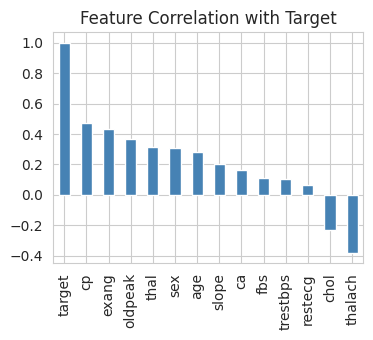

In [ ]:
#Target Correlation Plot
target_corr = (
    heart_df.corr()['target']
    .sort_values(ascending=False)
)

plt.figure(figsize=(4,3))

target_corr.plot(
    kind='bar',
    color='steelblue'
)

plt.title(
    "Feature Correlation with Target"
)

plt.show()

Observation - No single feature exhibits an extremely high correlation (>0.8) with the target, indicating that heart disease prediction will likely benefit from combining multiple clinical variables rather than relying on a single factor. The correlation analysis shows that thal, chest pain type (cp), exercise-induced angina (exang), and number of major vessels (ca) have the strongest positive relationships with heart disease occurrence. Variables such as oldpeak, slope, and sex exhibit moderate positive correlations with the target. On the other hand, maximum heart rate achieved (thalach) and cholesterol (chol) show negative correlations, indicating that higher values are associated with a lower likelihood of heart disease in this dataset.

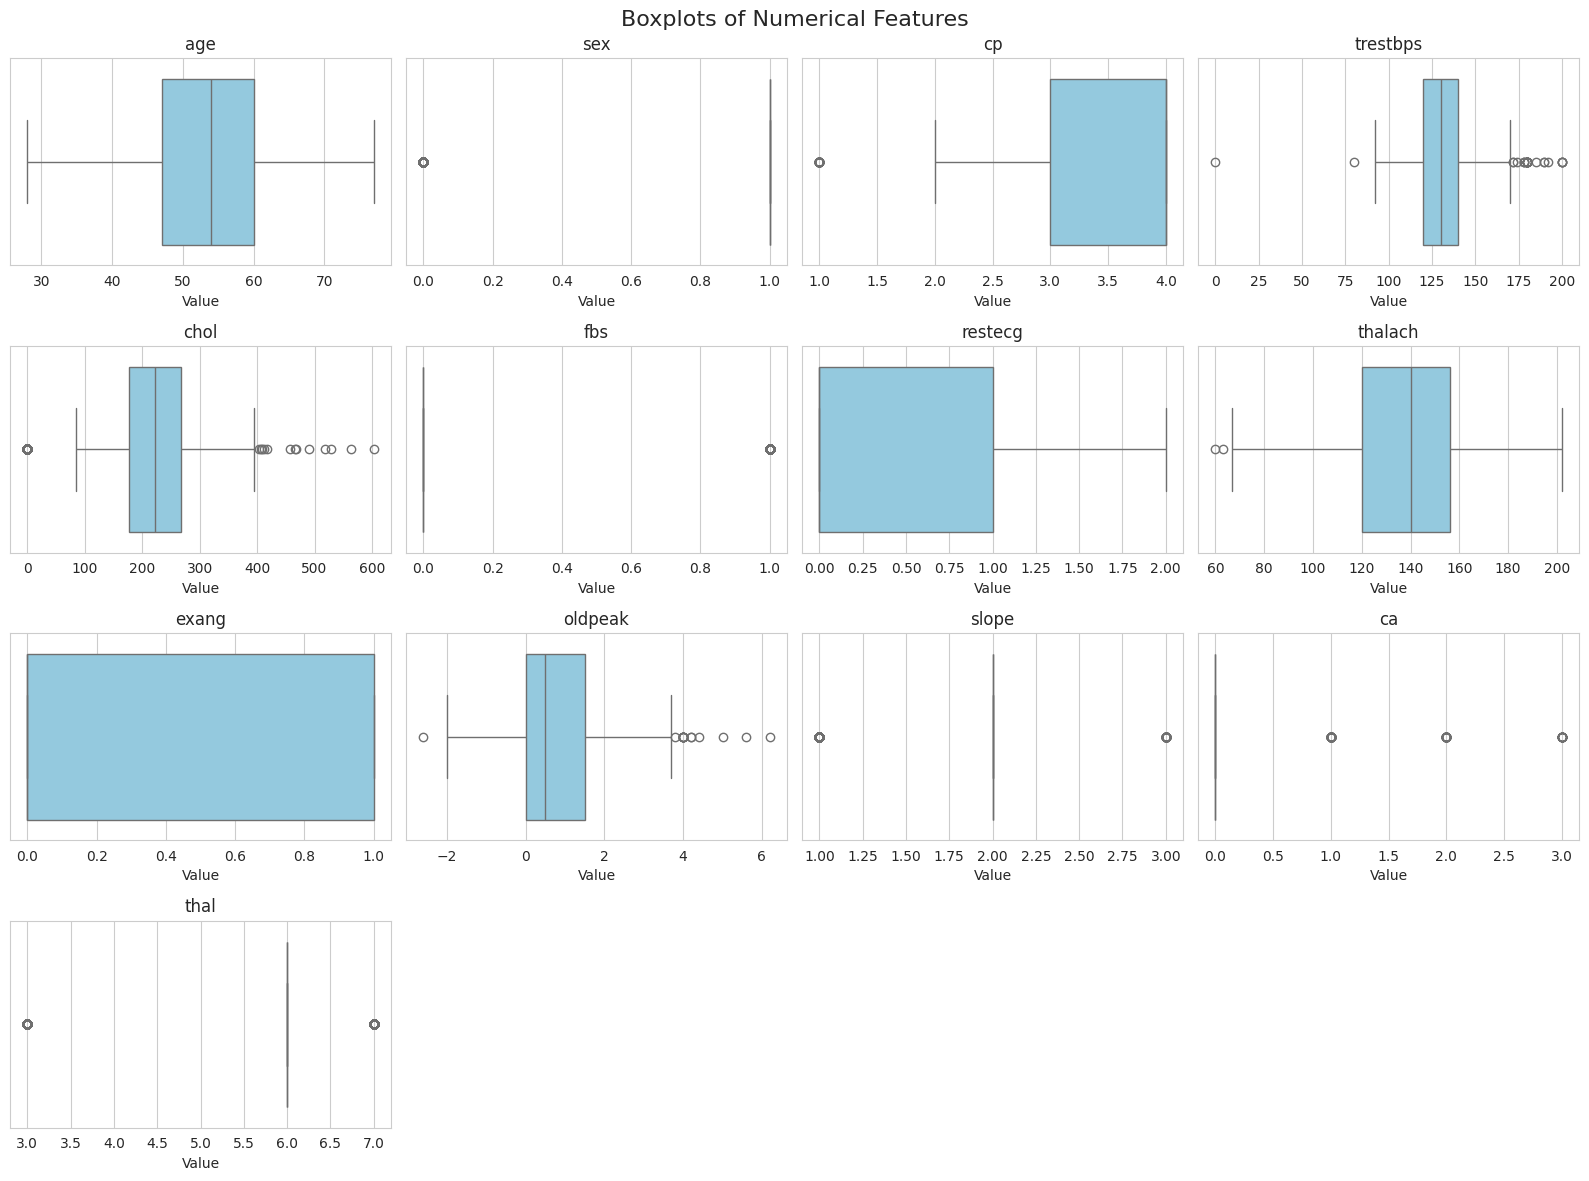

In [ ]:
#Boxplots for Outlier Detection
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    'age','sex','cp','trestbps','chol',
    'fbs','restecg','thalach',
    'exang','oldpeak','slope',
    'ca','thal'
]

fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(16,12)
)

axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(
        x=heart_df[col],
        ax=axes[i],
        color='skyblue'
    )
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")

# Remove empty subplot(s)
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Boxplots of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

Observation - Boxplot analysis indicates that cholesterol, resting blood pressure, and oldpeak contain several outliers. The age distribution is relatively consistent, while categorical features exhibit limited variability because of their discrete values. These observations suggest that outlier handling may be considered during model development.

**Task 2: Feature Engineering & Model Development**

In [ ]:
#Separate Features and Target
X = heart_df.drop('target', axis=1)
y = heart_df['target']

In [ ]:
#Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(736, 13)
(184, 13)


In [ ]:
#Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#Model 1: Logistic Regression
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_scaled,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
#Predictions
lr_pred = lr_model.predict(X_test_scaled)

lr_prob = lr_model.predict_proba(X_test_scaled)[:,1]

In [ ]:
#Evaluations
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

print("Accuracy:",
      accuracy_score(y_test, lr_pred))

print("Precision:",
      precision_score(y_test, lr_pred))

print("Recall:",
      recall_score(y_test, lr_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, lr_prob))

Accuracy: 0.8260869565217391
Precision: 0.8431372549019608
Recall: 0.8431372549019608
ROC-AUC: 0.8939502630320421


In [ ]:
#Cross Validation
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    scaler.fit_transform(X),
    y,
    cv=5,
    scoring='roc_auc'
)

print("Cross Validation ROC-AUC Scores:")
print(cv_scores)

print("Mean ROC-AUC:", cv_scores.mean())

Cross Validation ROC-AUC Scores:
[0.89275916 0.81384505 0.93424199 0.92706839 0.70851267]
Mean ROC-AUC: 0.8552854513641025


In [ ]:
#Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring='roc_auc'
)

grid_lr.fit(
    X_train_scaled,
    y_train
)

print("Best Parameters:",
      grid_lr.best_params_)

print("Best CV Score:",
      grid_lr.best_score_)

Best Parameters: {'C': 0.01}
Best CV Score: 0.8826813966922368


In [ ]:
#retrain using best parameters
best_lr = LogisticRegression(
    C=grid_lr.best_params_['C'],
    max_iter=1000,
    random_state=42
)

best_lr.fit(
    X_train_scaled,
    y_train
)

LogisticRegression(C=0.01, max_iter=1000, random_state=42)

In [ ]:
#Predictions
best_lr_pred = lr_model.predict(X_test_scaled)

best_lr_prob = lr_model.predict_proba(X_test_scaled)[:,1]

print("Accuracy:",
      accuracy_score(y_test, lr_pred))

print("Precision:",
      precision_score(y_test, lr_pred))

print("Recall:",
      recall_score(y_test, lr_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, lr_prob))

Accuracy: 0.8260869565217391
Precision: 0.8431372549019608
Recall: 0.8431372549019608
ROC-AUC: 0.8939502630320421


Note:- Logistic Regression was trained on standardized features because its optimization process is sensitive to feature magnitudes. Random Forest was trained on unscaled features because tree-based algorithms are invariant to feature scaling and make decisions based on split thresholds rather than distances.

In [ ]:
#Model 2: Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(random_state=42)

In [ ]:
#Predictions
rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
#Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Precision:",
      precision_score(y_test, rf_pred))

print("Recall:",
      recall_score(y_test, rf_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_prob))

Accuracy: 0.8315217391304348
Precision: 0.8380952380952381
Recall: 0.8627450980392157
ROC-AUC: 0.9197154471544715


In [ ]:
#Cross Validation
from sklearn.model_selection import cross_val_score

rf_cv_scores = cross_val_score(
    RandomForestClassifier(
        random_state=42
    ),
    X,
    y,
    cv=5,
    scoring='roc_auc'
)

print("Cross Validation ROC-AUC Scores:")
print(rf_cv_scores)

print("Mean ROC-AUC:")
print(rf_cv_scores.mean())

Cross Validation ROC-AUC Scores:
[0.9026005  0.78694405 0.88223338 0.83787661 0.68364419]
Mean ROC-AUC:
0.8186597463051347


In [ ]:
#Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring='roc_auc'
)

grid_rf.fit(
    X_train,
    y_train
)

print("Best Parameters:")
print(grid_rf.best_params_)

print("Best CV Score:")
print(grid_rf.best_score_)

Best Parameters:
{'max_depth': 5, 'n_estimators': 300}
Best CV Score:
0.8834313533500524


In [ ]:
#Retrain Using Best Parameters
best_rf = grid_rf.best_estimator_

best_rf.fit(
    X_train,
    y_train
)

best_rf_pred = best_rf.predict(X_test)

best_rf_prob = best_rf.predict_proba(
    X_test
)[:, 1]

print("Accuracy:",
      accuracy_score(y_test, best_rf_pred))

print("Precision:",
      precision_score(y_test, best_rf_pred))

print("Recall:",
      recall_score(y_test, best_rf_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, best_rf_prob))

Accuracy: 0.8369565217391305
Precision: 0.8333333333333334
Recall: 0.8823529411764706
ROC-AUC: 0.9268292682926829


In [ ]:
#Comparsion
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, best_lr_pred),
        accuracy_score(y_test, best_rf_pred)
    ],
    'Precision': [
        precision_score(y_test, best_lr_pred),
        precision_score(y_test, best_rf_pred)
    ],
    'Recall': [
        recall_score(y_test, best_lr_pred),
        precision_score(y_test, best_rf_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, best_lr_prob),
        roc_auc_score(y_test, best_rf_prob)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall   ROC-AUC
0  Logistic Regression  0.826087   0.843137  0.843137  0.893950
1        Random Forest  0.836957   0.833333  0.833333  0.926829


**Task 3 - Experiment Tracking**

In [ ]:
!pip install mlflow

In [ ]:
#Import Libraries
import mlflow
import mlflow.sklearn

In [ ]:
#Start MLflow Experiment
mlflow.set_experiment("Heart_Disease_Prediction")

2026/10/11 07:13:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/11 07:13:08 INFO mlflow.store.db.utils: Updating database tables
2026/10/11 07:13:12 INFO mlflow.tracking.fluent: Experiment with name 'Heart_Disease_Prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1791702792946, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791702792946, lifecycle_stage='active', name='Heart_Disease_Prediction', tags={}, trace_location=None, workspace='default'>

In [ ]:
#Experiment 1: Tuned Logistic Regression
with mlflow.start_run(
    run_name="Logistic_Regression"
):

    mlflow.log_param(
        "model",
        "LogisticRegression"
    )

    mlflow.log_param(
        "C",
        best_lr.get_params()['C']
    )

    accuracy = accuracy_score(
        y_test,
        best_lr_pred
    )

    precision = precision_score(
        y_test,
        best_lr_pred
    )

    recall = recall_score(
        y_test,
        best_lr_pred
    )

    roc_auc = roc_auc_score(
        y_test,
        best_lr_prob
    )

    mlflow.log_metric(
        "accuracy",
        accuracy
    )

    mlflow.log_metric(
        "precision",
        precision
    )

    mlflow.log_metric(
        "recall",
        recall
    )

    mlflow.log_metric(
        "roc_auc",
        roc_auc
    )

    mlflow.sklearn.log_model(
        sk_model=best_lr,
        artifact_path="model",
        serialization_format="pickle"
    )

    print("Logistic Regression logged")

2026/10/11 07:17:40 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/11 07:17:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression logged


In [ ]:
#Experiment 2: Tuned Random Forest
with mlflow.start_run(
    run_name="Random_Forest"
):

    mlflow.log_param(
        "model",
        "RandomForest"
    )

    mlflow.log_param(
        "n_estimators",
        best_rf.get_params()['n_estimators']
    )

    mlflow.log_param(
        "max_depth",
        best_rf.get_params()['max_depth']
    )

    accuracy = accuracy_score(
        y_test,
        best_rf_pred
    )

    precision = precision_score(
        y_test,
        best_rf_pred
    )

    recall = recall_score(
        y_test,
        best_rf_pred
    )

    roc_auc = roc_auc_score(
        y_test,
        best_rf_prob
    )

    mlflow.log_metric(
        "accuracy",
        accuracy
    )

    mlflow.log_metric(
        "precision",
        precision
    )

    mlflow.log_metric(
        "recall",
        recall
    )

    mlflow.log_metric(
        "roc_auc",
        roc_auc
    )

    mlflow.sklearn.log_model(
        sk_model=best_rf,
        artifact_path="model",
        serialization_format="pickle"
    )

    print("Random Forest logged")

2026/10/11 07:17:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/11 07:17:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest logged


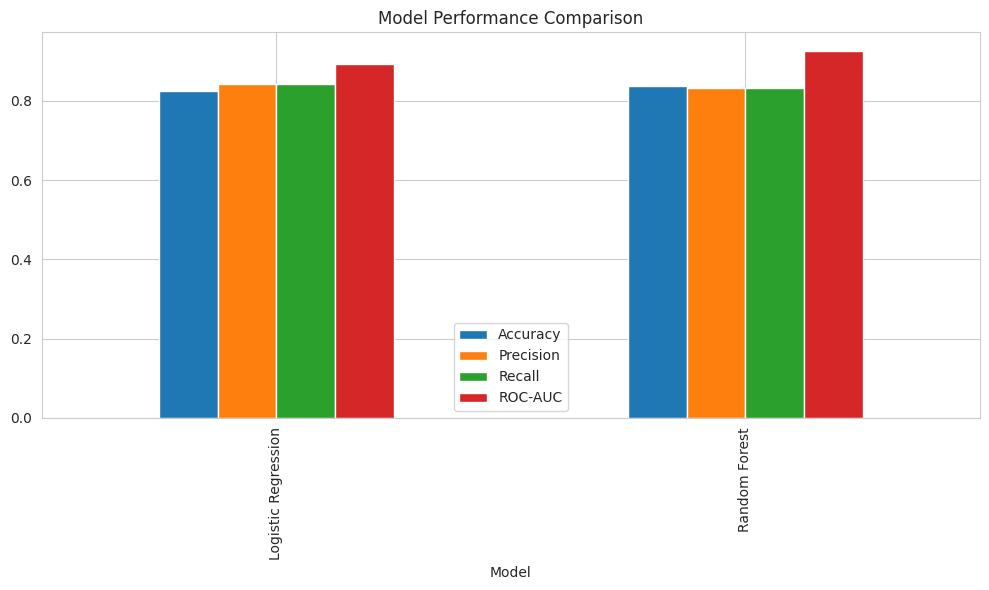

In [ ]:
#Log Comparison Plot (Artifact)
results.set_index('Model').plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("Model Performance Comparison")

plt.tight_layout()

plt.savefig("model_comparison.png")

plt.show()

with mlflow.start_run(run_name="Comparison_Plot"):
    mlflow.log_artifact("model_comparison.png")

In [ ]:
#Launch MLflow UI
!mlflow ui

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/11 07:19:36 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/11 07:19:36 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/11 07:19:37 INFO:     Uvicorn running on http://127.0.0.1:5000 (Press CTRL+C to quit)
2026/10/11 07:19:37 INFO:     Started parent process [35497]
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, bui

In [ ]:
runs = mlflow.search_runs()

display(
    runs[
        runs['tags.mlflow.runName'] != 'Comparison_Plot'
    ][[
        'tags.mlflow.runName',
        'metrics.accuracy',
        'metrics.precision',
        'metrics.recall',
        'metrics.roc_auc'
    ]]
)

,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.roc_auc
1,Random_Forest,0.836957,0.833333,0.882353,0.926829
2,Logistic_Regression,0.826087,0.843137,0.843137,0.893950
3,Random_Forest,0.836957,0.833333,0.882353,0.926829
4,Logistic_Regression,0.826087,0.843137,0.843137,0.893950
